# Mapping
### 11/11/2026

In [1]:
#get coordinates from OpenStreetMap
import pandas as pd
from geopy.geocoders import Nominatim
from geopy.extra.rate_limiter import RateLimiter

# Read your CSV
df = pd.read_csv("sioux_artworks_withstate_filtered.csv")

# Clean up state names
df["state"] = df["state"].str.strip()

# Initialize OpenStreetMap geocoder
geolocator = Nominatim(user_agent="sioux_artwork_geocoder")

# Add a 1-second delay between requests
geocode = RateLimiter(
    geolocator.geocode,
    min_delay_seconds=1
)

# Dictionary to store coordinates
coordinates = {}

# Geocode each unique state
for state in df["state"].dropna().unique():

    # Skip regional labels that aren't states
    if state in ["Great Plains", "Dakotas"]:
        continue

    location = geocode(f"{state}, USA")

    if location:
        coordinates[state] = {
            "latitude": location.latitude,
            "longitude": location.longitude
        }
    else:
        coordinates[state] = {
            "latitude": None,
            "longitude": None
        }

# Add latitude and longitude columns
df["latitude"] = df["state"].map(
    lambda x: coordinates.get(x, {}).get("latitude")
)

df["longitude"] = df["state"].map(
    lambda x: coordinates.get(x, {}).get("longitude")
)

# Export updated CSV
df.to_csv("sioux_artworks_with_coordinates.csv", index=False)

print(df[["state", "latitude", "longitude"]])


           state   latitude   longitude
0   Great Plains        NaN         NaN
1   Great Plains        NaN         NaN
2      Minnesota  45.989659  -94.611329
3   South Dakota  44.647176 -100.348761
4        Montana  47.375267 -109.638757
5        Dakotas        NaN         NaN
6   South Dakota  44.647176 -100.348761
7   South Dakota  44.647176 -100.348761
8   South Dakota  44.647176 -100.348761
9   South Dakota  44.647176 -100.348761
10  South Dakota  44.647176 -100.348761


In [2]:
import pandas as pd
import plotly.express as px

# Read your updated CSV
df = pd.read_csv("sioux_artworks_with_coordinates.csv")

# Remove rows without coordinates
df = df.dropna(subset=["latitude", "longitude"])

# Preview your data
df.head()

,objectID,isHighlight,accessionNumber,accessionYear,isPublicDomain,primaryImage,primaryImageSmall,additionalImages,constituents,department,...,linkResource,metadataDate,repository,objectURL,tags,objectWikidata_URL,isTimelineWork,GalleryNumber,latitude,longitude
2,319143,False,2011.154.112,2011,True,https://images.metmuseum.org/CRDImages/ad/orig...,https://images.metmuseum.org/CRDImages/ad/web-...,['https://images.metmuseum.org/CRDImages/ad/or...,NaN,The American Wing,...,NaN,2025-01-30T04:54:21.21Z,"Metropolitan Museum of Art, New York, NY",https://www.metmuseum.org/art/collection/searc...,"[{'term': 'Male Nudes', 'AAT_URL': 'http://voc...",NaN,False,NaN,45.989659,-94.611329
3,319188,False,"2011.154.152.1, .2",2011,True,https://images.metmuseum.org/CRDImages/ad/orig...,https://images.metmuseum.org/CRDImages/ad/web-...,['https://images.metmuseum.org/CRDImages/ad/or...,NaN,The American Wing,...,NaN,2025-01-30T04:54:21.21Z,"Metropolitan Museum of Art, New York, NY",https://www.metmuseum.org/art/collection/searc...,NaN,NaN,False,NaN,44.647176,-100.348761
4,319151,False,2011.154.12,2011,False,NaN,NaN,[],"[{'constituentID': 64068, 'role': 'Artist', 'n...",The American Wing,...,NaN,2026-09-04T04:58:44.81Z,"Metropolitan Museum of Art, New York, NY",https://www.metmuseum.org/art/collection/searc...,"[{'term': 'Horses', 'AAT_URL': 'http://vocab.g...",NaN,False,NaN,47.375267,-109.638757
6,751512,False,2019.456.27,2019,True,https://images.metmuseum.org/CRDImages/ad/orig...,https://images.metmuseum.org/CRDImages/ad/web-...,['https://images.metmuseum.org/CRDImages/ad/or...,NaN,The American Wing,...,NaN,2025-11-14T04:52:10.177Z,"Metropolitan Museum of Art, New York, NY",https://www.metmuseum.org/art/collection/searc...,NaN,https://www.wikidata.org/wiki/Q104413109,False,746.0,44.647176,-100.348761
7,751519,False,2019.456.8,2019,True,https://images.metmuseum.org/CRDImages/ad/orig...,https://images.metmuseum.org/CRDImages/ad/web-...,[],NaN,The American Wing,...,NaN,2025-12-13T04:50:44.133Z,"Metropolitan Museum of Art, New York, NY",https://www.metmuseum.org/art/collection/searc...,"[{'term': 'Flags', 'AAT_URL': 'http://vocab.ge...",https://www.wikidata.org/wiki/Q104413114,False,746.0,44.647176,-100.348761


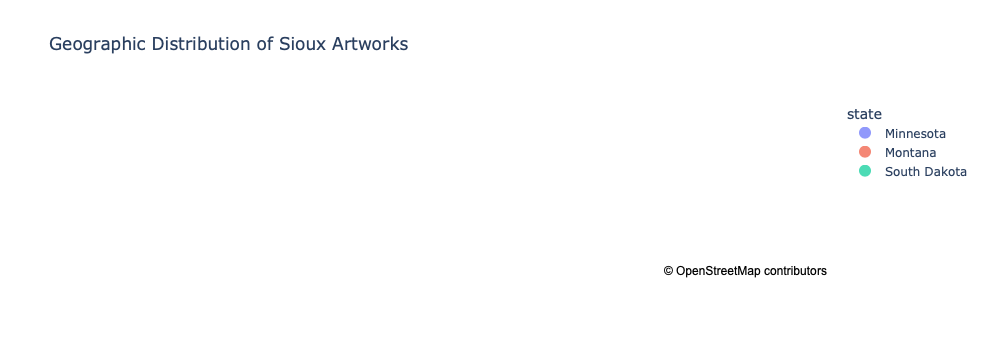

In [3]:
# Count artworks by state
state_summary = (
    df.groupby(["state", "latitude", "longitude"])
    .size()
    .reset_index(name="artwork_count")
)

# Create interactive map
fig = px.scatter_map(
    state_summary,
    lat="latitude",
    lon="longitude",
    color="state",
    size="artwork_count",
    size_max=25,
    hover_name="state",
    hover_data=["artwork_count"],
    zoom=3,
    center={"lat": 46, "lon": -100},
    map_style="open-street-map",
    title="Geographic Distribution of Sioux Artworks"
)

# Display map
fig.show()

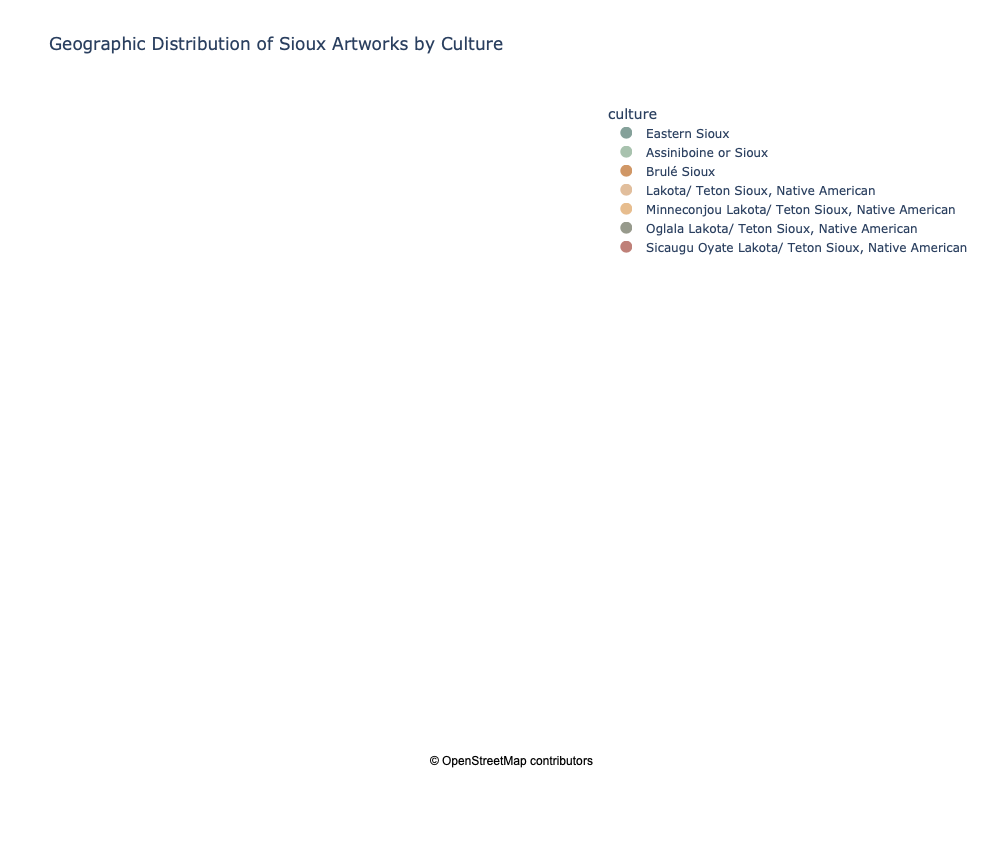

In [6]:
# I want to include the data from the 'culture column.' I decided to add Culture as I hovered over the bubbles, so I added 'culture' as another group.

custom_colors = {
    "Native American (Sioux, possibly)": "#8C564B",
    "Lakota/ Teton Sioux, Native American": "#D4A373",
    "Eastern Sioux": "#52796F",
    "Assiniboine or Sioux": "#84A98C",
    "Brulé Sioux": "#BC6C25",
    "Native American (Sioux)": "#606C38",
    "Minneconjou Lakota/ Teton Sioux, Native American": "#DDA15E",
    "Oglala Lakota/ Teton Sioux, Native American": "#6B705C",
    "Sicaugu Oyate Lakota/ Teton Sioux, Native American": "#A44A3F",
    "Unknown": "#808080"
}

# Replace missing culture values
df["culture"] = df["culture"].fillna("Unknown")

# Count artworks by state AND culture
culture_summary = (
    df.groupby(["state", "culture", "latitude", "longitude"])
    .size()
    .reset_index(name="artwork_count")
)

# Create interactive map
fig = px.scatter_map(
    culture_summary,
    lat="latitude",
    lon="longitude",
    color="culture",
    color_discrete_map=custom_colors,
    size="artwork_count",
    size_max=25,
    hover_name="culture",
    hover_data={
        "state": True,
        "artwork_count": True,
        "latitude": False,
        "longitude": False
    },
    zoom=3,
    center={"lat": 46, "lon": -100},
    map_style="open-street-map",
    title="Geographic Distribution of Sioux Artworks by Culture",
    height=850,
    width=1200
)

fig.show()


In [8]:
# I need to address the additional geographic information and decide what can be mapped and what can't. 
# I need to see if I can address regions as another layer

print(df.columns)

Index(['objectID', 'isHighlight', 'accessionNumber', 'accessionYear',
       'isPublicDomain', 'primaryImage', 'primaryImageSmall',
       'additionalImages', 'constituents', 'department', 'objectName', 'title',
       'culture', 'period', 'dynasty', 'reign', 'portfolio', 'artistRole',
       'artistPrefix', 'artistDisplayName', 'artistDisplayBio', 'artistSuffix',
       'artistAlphaSort', 'artistNationality', 'artistBeginDate',
       'artistEndDate', 'artistGender', 'artistWikidata_URL', 'artistULAN_URL',
       'objectDate', 'objectBeginDate', 'objectEndDate', 'medium',
       'dimensions', 'measurements', 'creditLine', 'geographyType', 'city',
       'state', 'county', 'country', 'region', 'subregion', 'locale', 'locus',
       'excavation', 'river', 'classification', 'rightsAndReproduction',
       'linkResource', 'metadataDate', 'repository', 'objectURL', 'tags',
       'objectWikidata_URL', 'isTimelineWork', 'GalleryNumber', 'latitude',
       'longitude'],
      dtype='object')

In [10]:
print(df[[ 'objectID', 'accessionNumber', 
    'geographyType',
    'city',
    'state',
    'county',
    'country',
    'region',
    'subregion',
    'locale',
    'locus',
    'excavation',
    'river'
]])

    objectID     accessionNumber     geographyType                    city  \
2     319143        2011.154.112      Object place                     NaN   
3     319188  2011.154.152.1, .2      Object place                     NaN   
4     319151         2011.154.12      Object place                     NaN   
6     751512         2019.456.27  Possibly made in                     NaN   
7     751519          2019.456.8  Possibly made in                     NaN   
8     717548          2017.718.2           Made in  Pine Ridge Reservation   
9     751520         2022.428.12           Made in  Pine Ridge Reservation   
10    751515          2018.867.6           Made in     Rosebud Reservation   

           state  county        country  region  subregion  locale  locus  \
2      Minnesota     NaN  United States     NaN        NaN     NaN    NaN   
3   South Dakota     NaN  United States     NaN        NaN     NaN    NaN   
4        Montana     NaN  United States     NaN        NaN     NaN

In [16]:
# Read the bigger CSV
df_all = pd.read_csv("nativeamerican_artworks_withstate_filtered.csv")


In [20]:
df_all['country'].value_counts()

country
United States    138
Canada           115
Guyana            12
Canada: N.A.       7
Brazil             2
Mexico             1
Name: count, dtype: int64

In [22]:
# to avoid the rate limit error
from geopy.extra.rate_limiter import RateLimiter

geocode = RateLimiter(
    geolocator.geocode,
    min_delay_seconds=1,
    max_retries=3,
    error_wait_seconds=5
)

# Read your CSV
df = pd.read_csv("nativeamerican_artworks_withstate_filtered.csv")

# Clean up state names
df["state"] = df["state"].str.strip()

# Initialize OpenStreetMap geocoder
geolocator = Nominatim(user_agent="nativeamerican_artwork_geocoder")

# Add a 1-second delay between requests
geocode = RateLimiter(
    geolocator.geocode,
    min_delay_seconds=1
)

# Dictionary to store coordinates
coordinates = {}

# Geocode each unique state
for state in df["state"].dropna().unique():

    # Skip regional labels that aren't states
    if state in ["British Columbia", 
    "Demerara", 
    "Ontario",
    "Great Plains",
    "Quebec",
    "Dakotas",
    "Matto Grosso",
    "Valley of Mexico",
    "Nova Scotia",
    "New Brunswick",
    "Amazonas province"]:
        continue

    location = geocode(f"{state}, USA")

    if location:
        coordinates[state] = {
            "latitude": location.latitude,
            "longitude": location.longitude
        }
    else:
        coordinates[state] = {
            "latitude": None,
            "longitude": None
        }

# Add latitude and longitude columns
df["latitude"] = df["state"].map(
    lambda x: coordinates.get(x, {}).get("latitude")
)

df["longitude"] = df["state"].map(
    lambda x: coordinates.get(x, {}).get("longitude")
)

# Export updated CSV
df.to_csv("nativeamerican_artworks_with_coordinates.csv", index=False)

print(df[["state", "latitude", "longitude"]])


                 state   latitude   longitude
0               Alaska  64.445961 -149.680909
1               Alaska  64.445961 -149.680909
2              Arizona  34.395342 -111.763275
3               Alaska  64.445961 -149.680909
4              Arizona  34.395342 -111.763275
5           New Mexico  34.580207 -105.996047
6           New Mexico  34.580207 -105.996047
7     British Columbia        NaN         NaN
8               Alaska  64.445961 -149.680909
9              Arizona  34.395342 -111.763275
10             Arizona  34.395342 -111.763275
11          New Mexico  34.580207 -105.996047
12              Alaska  64.445961 -149.680909
13            Demerara        NaN         NaN
14    British Columbia        NaN         NaN
15       New Brunswick        NaN         NaN
16             Dakotas        NaN         NaN
17         Nova Scotia        NaN         NaN
18            Demerara        NaN         NaN
19          New Mexico  34.580207 -105.996047
20              Alaska  64.445961 

In [25]:
import pandas as pd
import plotly.express as px

# Read your updated CSV
df2 = pd.read_csv("nativeamerican_artworks_with_coordinates.csv")

# Remove rows without coordinates
df2 = df2.dropna(subset=["latitude", "longitude"])

# Preview your data
df2.head()

,objectID,isHighlight,accessionNumber,accessionYear,isPublicDomain,primaryImage,primaryImageSmall,additionalImages,constituents,department,...,linkResource,metadataDate,repository,objectURL,tags,objectWikidata_URL,isTimelineWork,GalleryNumber,latitude,longitude
0,501180,False,89.4.564,1889.0,True,https://images.metmuseum.org/CRDImages/mi/orig...,https://images.metmuseum.org/CRDImages/mi/web-...,['https://images.metmuseum.org/CRDImages/mi/or...,NaN,Musical Instruments,...,NaN,2025-01-31T04:54:36.6Z,"Metropolitan Museum of Art, New York, NY",https://www.metmuseum.org/art/collection/searc...,NaN,NaN,False,NaN,64.445961,-149.680909
1,501197,False,89.4.581,1889.0,True,https://images.metmuseum.org/CRDImages/mi/orig...,https://images.metmuseum.org/CRDImages/mi/web-...,['https://images.metmuseum.org/CRDImages/mi/or...,NaN,Musical Instruments,...,NaN,2025-01-31T04:54:36.6Z,"Metropolitan Museum of Art, New York, NY",https://www.metmuseum.org/art/collection/searc...,NaN,NaN,False,NaN,64.445961,-149.680909
2,501200,False,89.4.584,1889.0,True,https://images.metmuseum.org/CRDImages/mi/orig...,https://images.metmuseum.org/CRDImages/mi/web-...,['https://images.metmuseum.org/CRDImages/mi/or...,NaN,Musical Instruments,...,NaN,2024-03-22T04:53:07.663Z,"Metropolitan Museum of Art, New York, NY",https://www.metmuseum.org/art/collection/searc...,NaN,NaN,False,NaN,34.395342,-111.763275
3,501203,False,89.4.587,1889.0,True,https://images.metmuseum.org/CRDImages/mi/orig...,https://images.metmuseum.org/CRDImages/mi/web-...,['https://images.metmuseum.org/CRDImages/mi/or...,NaN,Musical Instruments,...,NaN,2025-01-31T04:54:36.6Z,"Metropolitan Museum of Art, New York, NY",https://www.metmuseum.org/art/collection/searc...,NaN,NaN,False,NaN,64.445961,-149.680909
4,501205,False,89.4.589,1889.0,True,https://images.metmuseum.org/CRDImages/mi/orig...,https://images.metmuseum.org/CRDImages/mi/web-...,['https://images.metmuseum.org/CRDImages/mi/or...,NaN,Musical Instruments,...,NaN,2025-01-31T04:54:36.6Z,"Metropolitan Museum of Art, New York, NY",https://www.metmuseum.org/art/collection/searc...,NaN,NaN,False,NaN,34.395342,-111.763275


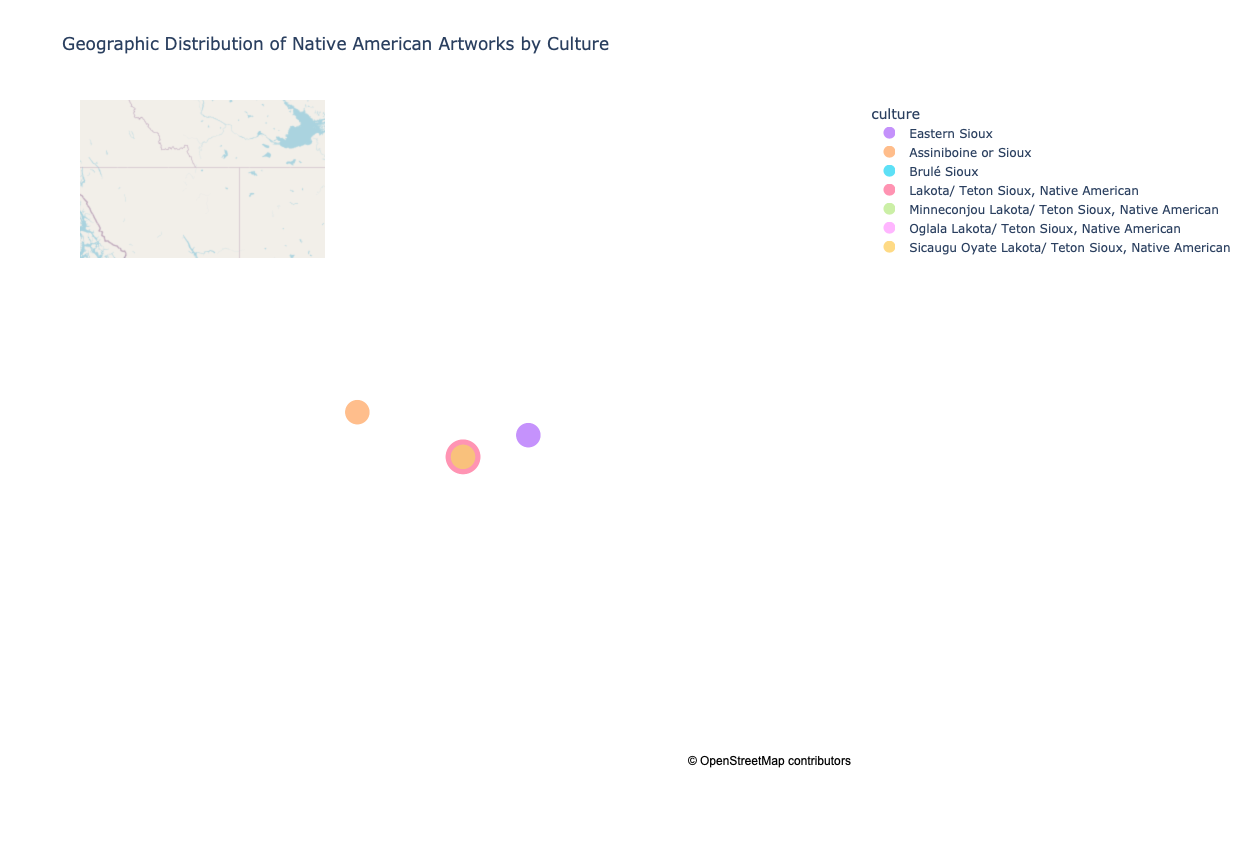

In [26]:
# I want to include the data from the 'culture column.' I decided to add Culture as I hovered over the bubbles, so I added 'culture' as another group.
# the dots will still be states

custom_colors = {
    "Alaska": "#8C564B",
    "Arizona": "#D4A373",
    "New Mexico": "#52796F",
    "Oklahoma": "#84A98C",
    "South Dakota": "#BC6C25",
    "Washington": "#606C38",
    "Wyoming": "#DDA15E",
    "Minnesota": "#6B705C",
    "Oregon": "#A44A3F",
    "Nevada": "#9C6644",
    "Alabama": "#588157",
    "Nebraska": "#C08552",
    "Maine": "#457B9D",
    "Utah": "#A98467",
    "Montana": "#386641",
    "Michigan": "#B56576",
    "Louisiana": "#6D597A",
    "Puerto Rico": "#E09F7D",
    "Ohio": "#4F6D7A",
    "Pennsylvania": "#A26769",
    "Wisconsin": "#7F8C69",
    "Iowa": "#CB997E",
    "Unknown": "#808080"
}

# Replace missing culture values
df2["culture"] = df2["culture"].fillna("Unknown")

# Count artworks by state and culture
culture_counts = (
    df2.groupby(["state", "culture"])
    .size()
    .unstack(fill_value=0)
)

# Count total artworks by state
state_summary = (
    df2.groupby("state")
    .agg(
        latitude=("latitude", "first"),
        longitude=("longitude", "first"),
        total_artworks=("state", "size")
    )
)

# Combine culture counts with state coordinates and totals
state_summary = state_summary.join(culture_counts)

# Preview results
state_summary.head()
# Create interactive map
fig = px.scatter_map(
    state_summary,
    lat="latitude",
    lon="longitude",
    color="state",
    color_discrete_map=custom_colors,
    size="total_artworks",
    size_max=25,
    hover_name="culture",
    hover_data={
        "state": True,
        "artwork_count": True,
        "latitude": False,
        "longitude": False
    },
    zoom=3,
    center={"lat": 46, "lon": -100},
    map_style="open-street-map",
    title="Geographic Distribution of Native American Artworks by State",
    height=850,
    width=1200
)

fig.show()
